# Round 4: relation-typed contrast at the classifier

Round 3 showed two things. **(1)** The CLIP-initialised classifier
(TA) with a zero-shot blend is far stronger than the earlier pipeline
(all 72.6, tail 77.7 mAP), but RTN on the image embeddings added
nothing on top of it. **(2)** Zero-shot CLIP confuses related classes
more than a trained classifier does (related-class gap 5.3 against
3.7), and TA inherits part of that: its class vectors start at the
class-name embeddings, where related classes such as *skis* and
*snowboard* sit almost on top of each other. RTN on the image
embeddings cannot pull those class vectors apart.

Round 4 therefore applies the relation types at the classifier:

1. **Relation-typed class contrast (ours).** For every label *k* of
   an image, the image's score for *k* competes in a softmax with its
   scores for the classes it does *not* have. A wrong class *c* for
   which images of *k* are confusable (relation value R[c, k]) gets
   weight 1 + alpha x R[c, k]. This pushes an image's scores for
   related wrong classes below its score for its own classes, and
   moves the related class vectors apart.
2. **Relation-typed margins (ours).** In the classification loss,
   the score of a wrong class *c* on an image is raised by
   m x R[c, k] (k = the image's labels) before the loss is computed,
   so related wrong classes must be pushed further down.
3. **Controls.** The same class contrast with uniform weights
   (alpha = 0) isolates the relation types; TA itself is the control
   for the margins.

Everything else is identical to round 3: CLIP-initialised classifier,
zero-shot blend, prompt ensemble, all 1,909 training images, 5-fold
cross-validation scored by (overall mAP + tail mAP) / 2, 10 seeds.
Round 3's saved runs are reused, so only the new variants are trained.

**Decision rule, fixed before running (as in round 3).** A
relation-typed variant is said to *improve* on a method if (a) tail AP
is higher, with a 95% interval above zero and a higher tail mAP in at
least 7 of 10 seeds; (b) the related-class false-positive gap is lower
under both controls (intervals below zero); (c) head AP drops by at
most 1 point. Verdict: WORKS (a, b and c), PARTLY ((a) or (b), with
(c)), NOT SHOWN (otherwise). Key tests: relation-typed class contrast
against uniform class contrast and against TA; relation-typed margins
against TA. **Round 4 is exploratory** (designed after seeing round
3): a gain here must be confirmed on a second dataset with every
setting fixed in advance.

## Step 0: setup

In [1]:
import hashlib
import importlib
import json
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from scipy import sparse

if not os.path.exists("context_reliance_check.py"):
    raise SystemExit("Put context_reliance_check.py in the same folder "
                     "as this notebook.")
import context_reliance_check as crc
importlib.reload(crc)
if not hasattr(crc, "related_labels"):
    raise SystemExit("context_reliance_check.py is an older version. "
                     "Replace it with the latest one.")
pd.set_option("display.max_colwidth", None)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"numpy {np.__version__}, pandas {pd.__version__}, "
      f"torch {torch.__version__}")
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"Device: {props.name} ({props.total_memory / 2**30:.1f} GB)")
else:
    print(f"Device: CPU (this PyTorch build has CUDA: {torch.version.cuda})")

numpy 2.5.4, pandas 3.1.0, torch 2.11.0+cu130
Device: NVIDIA GeForce RTX 4070 Laptop GPU (8.0 GB)


## Step 1: settings

In [2]:
DATA = "coco_mlt"
RUNS = os.path.join(DATA, "round3")   # saved runs, shared with round 3
OUT = os.path.join(DATA, "round4")
SEEDS = list(range(42, 52))   # 10 seeds for the final models
CV_FOLDS, FOLD_SEED, CV_RUN_SEED = 5, 0, 42
RELATED_PCT = 5               # related = top 5% most text-similar labels
BOOTSTRAP = 10000
RETRAIN = False               # True reruns everything, ignoring saved runs
ALLOW_CPU = False             # True lets the full run go ahead without a GPU
QUICK_TEST = False            # True = tiny run to test the code only
PROMPT_ENSEMBLE = "auto"      # "auto": use it if it scores better on the
                              # training images; True / False to force
MODEL_CACHE = "model_cache"   # folder holding ViT-B-16.pt

# Fixed settings of the CLIP-initialised classifier (TA)
TA_FIXED = dict(hidden=512, dropout=0.1, scale=20.0, lr=1e-3, wd=1e-4,
                batch=64, tau=0.1)
# Chosen by cross-validation, in this order:
GRID_TA = [dict(loss=l, epochs=e, cls_lr=c) for l in ("BCE", "ASL")
           for e in (10, 30, 90) for c in (0.0, 0.1, 1.0)]   # cls_lr 0 = text vectors fixed
GRID_SUPCON = [dict(lam=lam, q=q, alpha=0.0)
               for lam in (0.02, 0.05, 0.15) for q in (0.0, 0.5)]
GRID_RTN = [dict(lam=lam, q=q, alpha=a, target=t)
            for lam in (0.02, 0.05, 0.15) for q in (0.0, 0.5)
            for a in (2.0, 4.0, 8.0) for t in ("tail+medium", "all")]
# Round 4: relation types at the classifier
GRID_CC_UNI = [dict(cc=c, cc_alpha=0.0, q=q) for c in (0.1, 0.3, 1.0) for q in (0.0, 0.5)]
GRID_CC_RTN = [dict(cc=c, cc_alpha=a, q=q, target=t)
               for c in (0.1, 0.3, 1.0) for q in (0.0, 0.5)
               for a in (2.0, 4.0, 8.0) for t in ("tail+medium", "all")]
GRID_MARGIN = [dict(margin=m, target=t) for m in (0.5, 1.0, 2.0, 4.0)
               for t in ("tail+medium", "all")]
BETAS = [0.0, 0.25, 0.5, 1.0, 2.0, 4.0]   # zero-shot ensemble weights
LP_SETTINGS = {"BCE": (1e-3, 200), "ASL": (1e-3, 50)}   # context-check notebook

if QUICK_TEST:
    SEEDS, CV_FOLDS, BOOTSTRAP = [42, 43], 2, 200
    GRID_TA = [dict(loss="ASL", epochs=2, cls_lr=0.1), dict(loss="ASL", epochs=2, cls_lr=0.0)]
    GRID_SUPCON = [dict(lam=0.15, q=0.0, alpha=0.0)]
    GRID_RTN = [dict(lam=0.15, q=0.5, alpha=4.0, target="tail+medium"),
                dict(lam=0.15, q=0.0, alpha=4.0, target="all")]
    LP_SETTINGS = {"BCE": (1e-3, 2), "ASL": (1e-3, 2)}
    GRID_CC_UNI = [dict(cc=0.3, cc_alpha=0.0, q=0.0)]
    GRID_CC_RTN = [dict(cc=0.3, cc_alpha=4.0, q=0.5, target="tail+medium"),
                   dict(cc=1.0, cc_alpha=8.0, q=0.0, target="all")]
    GRID_MARGIN = [dict(margin=1.0, target="tail+medium")]

VARIANTS = [   # key, name
    ("zs", "Zero-shot CLIP (no training)"),
    ("lp_bce", "Linear probe, BCE"),
    ("lp_asl", "Linear probe, ASL"),
    ("ta", "CLIP-initialised adapter (TA)"),
    ("supcon", "TA + image contrast, uniform negatives (round 3)"),
    ("rtn", "TA + RTN on image embeddings (round 3)"),
    ("cc_uni", "TA + class contrast, uniform weights"),
    ("cc_rtn", "TA + relation-typed class contrast (ours)"),
    ("margin", "TA + relation-typed margins (ours)"),
]
NAME = dict(VARIANTS)
SHORT = {"zs": "Zero-shot", "lp_bce": "LP-BCE", "lp_asl": "LP-ASL", "ta": "TA",
         "supcon": "TA + image uniform", "rtn": "TA + image RTN",
         "cc_uni": "TA + class uniform", "cc_rtn": "TA + class RTN",
         "margin": "TA + RTN margins"}
CODE_VERSION = "round3-2026-11-02"
for sub in ("cv", "final"):
    os.makedirs(os.path.join(RUNS, sub), exist_ok=True)
os.makedirs(OUT, exist_ok=True)
if DEVICE == "cpu" and not (QUICK_TEST or ALLOW_CPU):
    raise SystemExit(
        "No GPU is visible to this notebook; the full run would take about "
        "2-3 hours on the CPU. Pick the kernel you used for the earlier "
        "notebooks (Kernel > Change kernel), or set ALLOW_CPU = True.")
print(f"New settings to cross-validate: {len(GRID_CC_UNI)} + {len(GRID_CC_RTN)} + "
      f"{len(GRID_MARGIN)} ({CV_FOLDS} folds), then {len(SEEDS)} seeds per method; "
      f"round 3's {len(GRID_TA) + len(GRID_SUPCON) + len(GRID_RTN)} settings are reused.")

New settings to cross-validate: 6 + 36 + 8 (5 folds), then 10 seeds per method; round 3's 60 settings are reused.


## Step 2: method code

Writes `rtn_clip_method.py` next to this notebook (round 3's code plus
the class contrast and the margins; round 3's settings behave exactly
as before, so its saved runs stay valid).

In [3]:
%%writefile rtn_clip_method.py
"""Round 3: relation-typed negatives (RTN) on a CLIP-initialised classifier.

Everything works on frozen CLIP ViT-B/16 features (L2-normalised image
embeddings) and the CLIP text embeddings of the class names, so one training
run takes seconds.

Model ("TA"): a residual adapter that starts as the identity, followed by a
cosine classifier whose class vectors start at the class-name text
embeddings. At initialisation it ranks images exactly as zero-shot CLIP does.
Loss: classification (BCE or ASL) + lambda x label-wise supervised
contrastive loss (MulSupCon's anchors: one per image and label) computed
against every training image, with relation-typed weights on the negatives.

Round 4 adds two classifier-level forms of RTN: a class contrast (each
positive label of an image against the other classes' vectors, related
classes weighted more) and relation-typed margins in the classification
loss. Settings without them behave exactly as in round 3.
"""
import math

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


# ------------------------------------------------------------- data utils ----
def iterative_split(Y, test_frac, seed):
    """Iterative stratification (Sechidis et al., 2011), two parts.
    Identical to round 1's function: 0 = fit, 1 = dev."""
    return iterative_folds(Y, None, seed, fracs=[1.0 - test_frac, test_frac])


def iterative_folds(Y, k, seed, fracs=None):
    """Iterative stratification into k folds of equal size (or the given
    fractions). Returns the fold index of every row."""
    rng = np.random.default_rng(seed)
    Y = np.asarray(Y, dtype=bool)
    n = Y.shape[0]
    frac = np.asarray(fracs if fracs is not None else [1.0 / k] * k, dtype=float)
    desired = frac * n
    desired_label = np.outer(frac, Y.sum(0)).astype(float)
    remaining = np.ones(n, dtype=bool)
    assign = -np.ones(n, dtype=int)
    while True:
        rem = Y[remaining].sum(0)
        if rem.sum() == 0:
            break
        label = int(np.argmin(np.where(rem > 0, rem, np.iinfo(np.int64).max)))
        idx = np.flatnonzero(remaining & Y[:, label])
        rng.shuffle(idx)
        for i in idx:
            d = desired_label[:, label]
            cand = np.flatnonzero(d == d.max())
            if cand.size > 1:
                ds = desired[cand]
                cand = cand[ds == ds.max()]
            s = int(rng.choice(cand)) if cand.size > 1 else int(cand[0])
            assign[i] = s
            remaining[i] = False
            desired_label[s] -= Y[i]
            desired[s] -= 1
    for i in np.flatnonzero(remaining):          # images without labels
        s = int(np.argmax(desired))
        assign[i] = s
        desired[s] -= 1
    return assign


def relation_masks(sim, shared, n_train, n_images, related_fn, pct,
                   min_shared=2, lift_min=2.0):
    """Relation types from training labels only (same as rounds 1 and 2):
    related & seen together, related & never together, informative companion,
    and 'any companion' (seen together at least once)."""
    L = sim.shape[0]
    rel_seen = np.zeros((L, L), bool)
    rel_never = np.zeros((L, L), bool)
    informative = np.zeros((L, L), bool)
    companion = np.zeros((L, L), bool)
    base = n_train / n_images
    for t in range(L):
        related = related_fn(sim[t], t, pct)
        for c in range(L):
            if c == t:
                continue
            k = shared[t, c]
            if k >= 1:
                companion[t, c] = True
            if related[c]:
                (rel_seen if k >= 1 else rel_never)[t, c] = True
            elif k >= min_shared and n_train[t] and base[c]:
                if (k / n_train[t]) / base[c] >= lift_min:
                    informative[t, c] = True
    return rel_seen, rel_never, informative, companion


def relation_values(Y, sim, related_fn, pct):
    """K x K relation values R[k, c] from the given training labels:
    1 = related & seen together, 0.5 = related & never together,
    0.25 = informative companion, 0 = anything else."""
    Yi = np.asarray(Y, dtype=np.int64)
    shared = Yi.T @ Yi
    masks = relation_masks(sim, shared, np.diag(shared).copy(), len(Yi), related_fn, pct)
    rel_seen, rel_never, informative, _ = masks
    R = np.zeros(shared.shape, dtype=np.float32)
    R[informative] = 0.25
    R[rel_never] = 0.5
    R[rel_seen] = 1.0
    return R, masks


def relation_scores(R, Y):
    """N x K: for image j and class k, the largest R[k, c] over j's labels c
    (how confusable image j is for class k)."""
    Yf = np.asarray(Y, dtype=np.float32)
    score = np.zeros((Yf.shape[0], R.shape[0]), dtype=np.float32)
    for v in np.unique(R[R > 0]):
        has = (Yf @ (R == v).T.astype(np.float32)) > 0.5
        score = np.maximum(score, v * has)
    return score


def candidate_weights(R, Y, alpha, target):
    """K x N weight of every training image j as a negative for anchor label
    k: 1 + alpha x max over j's labels c of R[k, c]. Positives (j has k) keep
    weight 1, and so do anchor labels outside `target` (a K-length bool)."""
    Yf = np.asarray(Y, dtype=np.float32)
    score = relation_scores(R, Yf)                                       # N x K
    W = 1.0 + alpha * score.T                                            # K x N
    W[Yf.T > 0.5] = 1.0
    W[~np.asarray(target, dtype=bool), :] = 1.0
    return W.astype(np.float32)


def row_weights(Y, q):
    """Weight of anchor rows with label k, proportional to n_k^-q and scaled
    so that the average over all anchor rows is 1 (q = 0: all equal)."""
    n = np.asarray(Y, dtype=np.float64).sum(0)
    w = np.where(n > 0, np.maximum(n, 1.0) ** (-q), 0.0)
    return (w / ((n * w).sum() / n.sum())).astype(np.float32)


def standardise_by(train_scores, scores):
    """Per-class standardisation with statistics of the training images."""
    mu = train_scores.mean(0, keepdims=True)
    sd = train_scores.std(0, keepdims=True) + 1e-6
    return (scores - mu) / sd


# ----------------------------------------------------------------- losses ----
def bce_mean(logits, y):
    """BCE averaged over all entries (the linear-probe reference)."""
    return F.binary_cross_entropy_with_logits(logits, y)


def bce_sum(logits, y):
    """BCE summed over classes, averaged over images (same scale as ASL)."""
    return F.binary_cross_entropy_with_logits(logits, y, reduction="none").sum(1).mean()


def asl_sum(logits, y, gamma_neg=4.0, gamma_pos=0.0, clip=0.05, eps=1e-8):
    """Asymmetric loss (Ridnik et al., 2021) with the usual settings, as in
    the context-check notebook."""
    p = torch.sigmoid(logits)
    p_neg = (1 - p + clip).clamp(max=1)
    log_terms = (y * torch.log(p.clamp(min=eps))
                 + (1 - y) * torch.log(p_neg.clamp(min=eps)))
    pt = p * y + p_neg * (1 - y)
    focus = torch.pow(1 - pt, gamma_pos * y + gamma_neg * (1 - y))
    return -(log_terms * focus).sum(1).mean()


def label_supcon(z_all, y_all, idx, W, row_w, tau):
    """Label-wise supervised contrastive loss with weighted negatives.

    Anchors: every (image i in the batch `idx`, label k of i). Candidates:
    every training image except i. Positives: candidates with label k;
    negatives: the others, weighted by W[k, j] (W = 1 gives MulSupCon's
    uniform loss). Row loss: log(sum_pos e^s + sum_neg W e^s) - mean_pos s,
    with s = cosine / tau; rows are averaged with weights row_w[k].
    z_all: N x d (unit vectors), y_all: N x K (0/1 float), W: K x N."""
    z_b = z_all[idx]
    S = z_b @ z_all.T / tau                                   # B x N
    self_mask = F.one_hot(idx, S.shape[1]).bool()
    m = S.max(dim=1, keepdim=True).values.detach()
    E = torch.exp(S - m).masked_fill(self_mask, 0.0)
    den = m + torch.log((E @ W.T).clamp_min(1e-30))            # B x K
    y_b = y_all[idx]
    s_self = S.gather(1, idx.view(-1, 1))
    pos_sum = S @ y_all - s_self * y_b                        # self excluded
    n_pos = y_all.sum(0, keepdim=True) - y_b
    rows = (y_b > 0.5) & (n_pos > 0.5)
    ell = den - pos_sum / n_pos.clamp_min(1.0)
    w = row_w.view(1, -1).expand_as(ell)
    return (ell * w)[rows].sum() / w[rows].sum().clamp_min(1e-12)


def label_supcon_reference(z_all, y_all, idx, W, row_w, tau):
    """Row-by-row definition of label_supcon, for the self-test."""
    total, wsum = 0.0, 0.0
    N, K = y_all.shape
    for i in idx.tolist():
        s = z_all[i] @ z_all.T / tau
        others = [j for j in range(N) if j != i]
        for k in range(K):
            if y_all[i, k] < 0.5:
                continue
            pos = [j for j in others if y_all[j, k] > 0.5]
            if not pos:
                continue
            den = torch.log(sum(W[k, j] * torch.exp(s[j]) for j in others))
            ell = -sum(s[p] - den for p in pos) / len(pos)
            total = total + row_w[k] * ell
            wsum = wsum + row_w[k]
    return total / wsum


def class_contrast_weights(R, alpha, target):
    """K x K weights for the class contrast: Om[k, c] = 1 + alpha x R[c, k]
    for a negative class c when the image has label k (images of k are
    confusable for c), applied only to classes c in `target`."""
    tgt = np.asarray(target, dtype=np.float32)
    return (1.0 + alpha * R.T * tgt[None, :]).astype(np.float32)


def relation_class_contrast(cos_logits, y, Om, row_w):
    """For every positive label k of an image:
    -log(e^{l_k} / (e^{l_k} + sum over negative classes c of Om[k, c] e^{l_c})),
    with l = scale x cosine to the class vectors (no bias). The image's other
    positive labels are left out. Om = 1 gives the uniform class contrast."""
    m = cos_logits.max(dim=1, keepdim=True).values.detach()
    E = torch.exp(cos_logits - m)
    neg = (E * (1 - y)) @ Om.T                                  # B x K
    ell = m + torch.log(E + neg) - cos_logits
    rows = y > 0.5
    w = row_w.view(1, -1).expand_as(ell)
    return (ell * w)[rows].sum() / w[rows].sum().clamp_min(1e-12)


def relation_class_contrast_reference(cos_logits, y, Om, row_w):
    """Row-by-row definition of relation_class_contrast, for the self-test."""
    total, wsum = 0.0, 0.0
    B, K = y.shape
    for b in range(B):
        for k in range(K):
            if y[b, k] < 0.5:
                continue
            den = torch.exp(cos_logits[b, k]) + sum(
                Om[k, c] * torch.exp(cos_logits[b, c]) for c in range(K) if y[b, c] < 0.5)
            total = total + row_w[k] * (torch.log(den) - cos_logits[b, k])
            wsum = wsum + row_w[k]
    return total / wsum


# ------------------------------------------------------------------ model ----
class TextAdapter(nn.Module):
    """Residual adapter (identity at start) + cosine classifier initialised
    with the class-name text embeddings, with a learned scale and per-class
    bias set so that initial probabilities match the class priors."""

    def __init__(self, T, prior_logit, zs_center, hidden=512, dropout=0.1, scale=20.0):
        super().__init__()
        d = T.shape[1]
        self.fc1 = nn.Linear(d, hidden)
        self.fc2 = nn.Linear(hidden, d)
        nn.init.zeros_(self.fc2.weight)
        nn.init.zeros_(self.fc2.bias)
        self.drop = nn.Dropout(dropout)
        self.register_buffer("T0", F.normalize(T, dim=-1))
        self.delta = nn.Parameter(torch.zeros_like(self.T0))
        self.log_scale = nn.Parameter(torch.tensor(math.log(scale)))
        self.bias = nn.Parameter(prior_logit - scale * zs_center)

    def embed(self, x):
        return F.normalize(x + self.fc2(self.drop(F.relu(self.fc1(x)))), dim=-1)

    def class_vectors(self):
        return F.normalize(self.T0 + self.delta, dim=-1)

    def logits_from(self, z):
        return self.log_scale.exp() * z @ self.class_vectors().T + self.bias


def make_text_adapter(X, Y, T, cfg, device):
    p = np.clip(np.asarray(Y, dtype=np.float64).mean(0), 1e-4, 1 - 1e-4)
    prior_logit = torch.as_tensor(np.log(p / (1 - p)), dtype=torch.float32)
    zs_center = torch.as_tensor((np.asarray(X) @ np.asarray(T).T).mean(0), dtype=torch.float32)
    return TextAdapter(torch.as_tensor(T, dtype=torch.float32), prior_logit, zs_center,
                       cfg["hidden"], cfg["dropout"], cfg["scale"]).to(device)


# --------------------------------------------------------------- training ----
def train_text_adapter(X, Y, T, cfg, seed, device, R=None, target=None, eval_X=()):
    """Train the CLIP-initialised classifier on (X, Y). cfg keys: loss
    ('BCE'/'ASL'), epochs, lr, wd, batch, hidden, dropout, scale, tau, lam
    (0 = no contrastive term), alpha (0 = uniform negatives), q, target,
    cls_lr (learning-rate multiplier for the class vectors; 0 keeps them
    at the CLIP text embeddings).

    Returns, for every array in eval_X, the pair (trained, zero_shot) of
    per-class standardised scores (statistics from the training images)."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    N, K = Y.shape
    Xt = torch.as_tensor(X, dtype=torch.float32, device=device)
    Yt = torch.as_tensor(Y, dtype=torch.float32, device=device)
    model = make_text_adapter(X, Y, T, cfg, device)
    groups = [{"params": [*model.fc1.parameters(), *model.fc2.parameters(),
                          model.log_scale, model.bias], "lr": cfg["lr"]}]
    cls_lr = float(cfg.get("cls_lr", 1.0))
    if cls_lr > 0:
        groups.append({"params": [model.delta], "lr": cfg["lr"] * cls_lr})
    else:
        model.delta.requires_grad_(False)
    opt = torch.optim.AdamW(groups, lr=cfg["lr"], weight_decay=cfg["wd"])
    steps = cfg["epochs"] * math.ceil(N / cfg["batch"])
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: 0.5 * (1.0 + math.cos(math.pi * min(s, steps) / steps)))
    cls_loss = {"BCE": bce_sum, "ASL": asl_sum}[cfg["loss"]]
    lam = float(cfg.get("lam", 0.0))
    if lam > 0:
        tgt = np.ones(K, bool) if target is None else np.asarray(target, bool)
        Rr = R if R is not None else np.zeros((K, K), np.float32)
        W = torch.as_tensor(candidate_weights(Rr, Y, float(cfg.get("alpha", 0.0)), tgt),
                            device=device)
        rw = torch.as_tensor(row_weights(Y, float(cfg.get("q", 0.0))), device=device)
    lam_c = float(cfg.get("cc", 0.0))          # class contrast weight (round 4)
    margin = float(cfg.get("margin", 0.0))     # relation-typed margin (round 4)
    if lam_c > 0 or margin > 0:
        tgt_c = np.ones(K, bool) if target is None else np.asarray(target, bool)
        Rc = R if R is not None else np.zeros((K, K), np.float32)
    if lam_c > 0:
        Om = torch.as_tensor(class_contrast_weights(Rc, float(cfg.get("cc_alpha", 0.0)), tgt_c),
                             device=device)
        rw_c = torch.as_tensor(row_weights(Y, float(cfg.get("q", 0.0))), device=device)
    if margin > 0:
        Mg = torch.as_tensor(margin * relation_scores(Rc, Y) * tgt_c[None, :]
                             * (1.0 - np.asarray(Y, dtype=np.float32)), device=device)
    model.train()
    for _ in range(cfg["epochs"]):
        order = rng.permutation(N)
        for start in range(0, N, cfg["batch"]):
            b = torch.as_tensor(order[start:start + cfg["batch"]], device=device)
            if lam_c > 0 or margin > 0:
                z_all = model.embed(Xt) if lam > 0 else None
                z_b = z_all[b] if lam > 0 else model.embed(Xt[b])
                logits = model.logits_from(z_b)
                loss = cls_loss(logits + Mg[b] if margin > 0 else logits, Yt[b])
                if lam > 0:
                    loss = loss + lam * label_supcon(z_all, Yt, b, W, rw, cfg["tau"])
                if lam_c > 0:
                    cos_l = model.log_scale.exp() * z_b @ model.class_vectors().T
                    loss = loss + lam_c * relation_class_contrast(cos_l, Yt[b], Om, rw_c)
            elif lam > 0:
                z_all = model.embed(Xt)                   # every image, with gradient
                loss = (cls_loss(model.logits_from(z_all[b]), Yt[b])
                        + lam * label_supcon(z_all, Yt, b, W, rw, cfg["tau"]))
            else:
                loss = cls_loss(model.logits_from(model.embed(Xt[b])), Yt[b])
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
    model.eval()
    with torch.no_grad():
        def scores(A):
            At = torch.as_tensor(A, dtype=torch.float32, device=device)
            return (model.logits_from(model.embed(At)).cpu().numpy().astype(np.float64),
                    (At @ model.T0.T).cpu().numpy().astype(np.float64))
        tr_t, tr_z = scores(X)
        out = []
        for A in eval_X:
            t, z = scores(A)
            out.append((standardise_by(tr_t, t), standardise_by(tr_z, z)))
    return out


def train_linear_probe(X_std, Y, loss_name, lr, epochs, seed, device, X_zs_train,
                       T, eval_X=(), eval_X_zs=(), batch=64, wd=1e-4):
    """Linear head on standardised features, exactly as in the context-check
    notebook (same seeds give the same model). Returns standardised
    (trained, zero_shot) scores like train_text_adapter; zero-shot scores use
    the unstandardised (L2-normalised) features."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    loss_fn = {"BCE": bce_mean, "ASL": asl_sum}[loss_name]
    Xt = torch.as_tensor(X_std, dtype=torch.float32, device=device)
    Yt = torch.as_tensor(Y, dtype=torch.float32, device=device)
    head = nn.Linear(X_std.shape[1], Y.shape[1]).to(device)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=wd)
    for _ in range(epochs):
        order = rng.permutation(len(Y))
        for start in range(0, len(order), batch):
            b = torch.as_tensor(order[start:start + batch], device=device)
            loss = loss_fn(head(Xt[b]), Yt[b])
            opt.zero_grad()
            loss.backward()
            opt.step()
    with torch.no_grad():
        f = lambda A: head(torch.as_tensor(A, dtype=torch.float32, device=device)).cpu().numpy()
        tr_t = f(X_std).astype(np.float64)
        tr_z = np.asarray(X_zs_train, dtype=np.float64) @ np.asarray(T, dtype=np.float64).T
        out = []
        for A, Az in zip(eval_X, eval_X_zs):
            z = np.asarray(Az, dtype=np.float64) @ np.asarray(T, dtype=np.float64).T
            out.append((standardise_by(tr_t, f(A).astype(np.float64)), standardise_by(tr_z, z)))
    return out

Overwriting rtn_clip_method.py


In [4]:
import rtn_clip_method as rc3
importlib.reload(rc3)
print("Loaded rtn_clip_method.py")

Loaded rtn_clip_method.py


## Step 3: data, relation types and self-tests

The self-tests check that (1) the relation types computed here match
rounds 1-2 on the same 1,516-image split; (2) the fast contrastive
loss equals its row-by-row definition, in value and gradient, and
weights of 1 give the uniform loss; (3) the CLIP-initialised
classifier, before training, ranks images exactly as zero-shot CLIP;
(4) the new class contrast equals its row-by-row definition.

In [5]:
IN, FEAT = os.path.join(DATA, "check_inputs"), os.path.join(DATA, "features")
files = {"training labels": os.path.join(IN, "training_positives.npz"),
         "evaluation labels": os.path.join(IN, "val_positives.npz"),
         "label table": os.path.join(IN, "labels.csv"),
         "training features": os.path.join(FEAT, "train_features.npy"),
         "evaluation features": os.path.join(FEAT, "val_features.npy"),
         "text embeddings": os.path.join(FEAT, "label_text_embeddings.npy")}
missing = [p for p in files.values() if not os.path.exists(p)]
if missing:
    raise SystemExit("Missing (run coco_mlt_context_check.ipynb first): "
                     + ", ".join(missing))
Y_all = sparse.load_npz(files["training labels"]).toarray().astype(np.float32)
Y_test = np.load(files["evaluation labels"])["positives"].astype(np.float32)
X_all = np.load(files["training features"]).astype(np.float32)
X_test = np.load(files["evaluation features"]).astype(np.float32)
T_SINGLE = np.load(files["text embeddings"]).astype(np.float32)
labels_df = pd.read_csv(files["label table"])
names = labels_df["display_name"].tolist()
cohort = labels_df["cohort"].to_numpy()
L = len(names)
norms = np.linalg.norm(X_all, axis=1)
if np.abs(norms - 1).max() > 1e-3:
    print("Features were not unit length; normalising them.")
    X_all /= np.linalg.norm(X_all, axis=1, keepdims=True)
    X_test /= np.linalg.norm(X_test, axis=1, keepdims=True)
T_SINGLE /= np.linalg.norm(T_SINGLE, axis=1, keepdims=True)
sim = crc.text_similarity(files["text embeddings"], None, L)
GROUPS = {g: np.flatnonzero(cohort == g) for g in ("head", "medium", "tail")}
GROUPS["all"] = np.arange(L)
TAIL = GROUPS["tail"]
TARGET = {"all": np.ones(L, bool), "tail+medium": cohort != "head"}
print(f"Training images {len(Y_all)}, evaluation images {len(Y_test)}, "
      f"classes {L} (head {len(GROUPS['head'])}, medium "
      f"{len(GROUPS['medium'])}, tail {len(TAIL)})")

# Relation types from all 1,909 training images (used by the final models)
R_ALL, MASKS_ALL = rc3.relation_values(Y_all, sim, crc.related_labels, RELATED_PCT)
rows = []
for g in ("head", "medium", "tail"):
    c = GROUPS[g]
    rows.append(dict(cohort=g, related_seen=int(MASKS_ALL[0][c].sum()),
                     related_never=int(MASKS_ALL[1][c].sum()),
                     informative=int(MASKS_ALL[2][c].sum())))
print("Relation pairs per cohort, all 1,909 training images:")
display(pd.DataFrame(rows))

# Self-test 1: same relation types as rounds 1-2 on their split
split = rc3.iterative_split(Y_all, 0.2, 0)
_, m1516 = rc3.relation_values(Y_all[split == 0], sim, crc.related_labels, RELATED_PCT)
r12 = {"head": (79, 9, 166), "medium": (72, 60, 159), "tail": (23, 77, 44)}
same = all(tuple(int(m[GROUPS[g]].sum()) for m in m1516[:3]) == r12[g]
           for g in r12)
# Self-test 2: fast loss = row-by-row definition (value, gradient)
g = torch.Generator().manual_seed(0)
zt = torch.nn.functional.normalize(torch.randn(30, 8, generator=g,
                                               dtype=torch.float64), dim=1)
zt.requires_grad_(True)
yt = (torch.rand(30, 5, generator=g) < 0.35).double()
yt[0] = 1
Wt = (1 + torch.randint(0, 3, (5, 30), generator=g).double()) * (1 - yt.T) + yt.T
rwt = torch.rand(5, generator=g, dtype=torch.float64) + 0.5
it = torch.tensor([0, 4, 9, 17])
a = rc3.label_supcon(zt, yt, it, Wt, rwt, 0.1)
b = rc3.label_supcon_reference(zt, yt, it, Wt, rwt, 0.1)
ga, = torch.autograd.grad(a, zt)
gb, = torch.autograd.grad(b, zt)
u1 = rc3.label_supcon(zt, yt, it, torch.ones_like(Wt), rwt, 0.1)
u2 = rc3.label_supcon_reference(zt, yt, it, torch.ones_like(Wt), rwt, 0.1)
lc = torch.randn(6, 7, generator=g, dtype=torch.float64).requires_grad_(True)
yc = (torch.rand(6, 7, generator=g) < 0.35).double()
yc[:, 0] = 1
Omc = torch.as_tensor(rc3.class_contrast_weights(
    np.random.default_rng(2).choice([0, 0.25, 0.5, 1.0], (7, 7)).astype(np.float32),
    4.0, np.ones(7, bool)), dtype=torch.float64)
rwc = torch.rand(7, generator=g, dtype=torch.float64) + 0.5
c1 = rc3.relation_class_contrast(lc, yc, Omc, rwc)
c2 = rc3.relation_class_contrast_reference(lc, yc, Omc, rwc)
gc1, = torch.autograd.grad(c1, lc)
gc2, = torch.autograd.grad(c2, lc)
# Self-test 3: untrained classifier ranks like zero-shot CLIP
_m = rc3.make_text_adapter(X_all, Y_all, T_SINGLE, TA_FIXED, "cpu").eval()
with torch.no_grad():
    _s = _m.logits_from(_m.embed(torch.as_tensor(X_all))).numpy()
_zs = X_all @ T_SINGLE.T
ap_gap = max(abs(crc.average_precision(_s[:, j], Y_all[:, j])
                 - crc.average_precision(_zs[:, j], Y_all[:, j])) for j in range(L))
checks = pd.DataFrame([
    ("relation types match rounds 1-2 (1,516-image split)", same),
    ("contrastive loss equals the row-by-row definition",
     bool(torch.allclose(a, b))),
    ("its gradient equals the row-by-row gradient", bool(torch.allclose(ga, gb))),
    ("weights of 1 give the uniform loss", bool(torch.allclose(u1, u2))),
    ("untrained classifier ranks like zero-shot CLIP", ap_gap < 1e-4),
    ("class contrast equals its row-by-row definition (value, gradient)",
     bool(torch.allclose(c1, c2) and torch.allclose(gc1, gc2))),
], columns=["check", "passed"])
display(checks)
if not checks["passed"].all():
    raise SystemExit("A self-test failed; please send me this notebook as it is.")

Training images 1909, evaluation images 5000, classes 80 (head 22, medium 33, tail 25)
Relation pairs per cohort, all 1,909 training images:


,cohort,related_seen,related_never,informative
0,head,79,9,161
1,medium,79,53,152
2,tail,27,73,45


,check,passed
0,"relation types match rounds 1-2 (1,516-image split)",True
1,contrastive loss equals the row-by-row definition,True
2,its gradient equals the row-by-row gradient,True
3,weights of 1 give the uniform loss,True
4,untrained classifier ranks like zero-shot CLIP,True
5,"class contrast equals its row-by-row definition (value, gradient)",True


## Step 4: class-name embeddings and zero-shot CLIP

The single-prompt embeddings ("a photo of a ...") define the relation
types, as before. For the classifier, an average over several prompts
often works better; if the CLIP model is available, both are scored
on the *training* images (no test data) and the better one is used.

In [6]:
TEMPLATES = ["a photo of a {}.", "a photo of the {}.", "a photo of one {}.",
             "a photo of many {}.", "a cropped photo of a {}.",
             "a close-up photo of a {}.", "a photo of a small {}.",
             "a photo of a large {}.", "a blurry photo of a {}.",
             "a bright photo of a {}.", "a good photo of a {}.",
             "a photo containing a {}.", "there is a {} in the scene.",
             "a {} in the scene."]
ENS_PATH = os.path.join(FEAT, "label_text_embeddings_prompt_ensemble.npy")


def class_ap(S, Y):
    return np.array([crc.average_precision(S[:, j], Y[:, j])
                     if Y[:, j].any() else np.nan for j in range(Y.shape[1])])


def group_map(ap, g):
    return 100 * float(np.nanmean(ap[GROUPS[g]]))


T_ENS = None
if PROMPT_ENSEMBLE:
    if os.path.exists(ENS_PATH):
        T_ENS = np.load(ENS_PATH).astype(np.float32)
    else:
        try:
            import clip
            _model, _ = clip.load("ViT-B/16", device=DEVICE, download_root=MODEL_CACHE)
            embs = []
            with torch.no_grad():
                for n in names:
                    tok = clip.tokenize([t.format(n) for t in TEMPLATES]).to(DEVICE)
                    e = _model.encode_text(tok).float()
                    e = e / e.norm(dim=-1, keepdim=True)
                    embs.append((e.mean(0) / e.mean(0).norm()).cpu().numpy())
            T_ENS = np.stack(embs).astype(np.float32)
            np.save(ENS_PATH, T_ENS)
            del _model
        except Exception as e:   # no clip package or no model file
            print(f"Prompt ensemble skipped ({type(e).__name__}: {e}).")
rows, choice = [], "single prompt"
for label, T in (("single prompt", T_SINGLE), ("prompt ensemble", T_ENS)):
    if T is None:
        continue
    ap_tr = class_ap(X_all @ T.T, Y_all)
    rows.append(dict(embeddings=label, **{f"training {g} mAP": round(group_map(ap_tr, g), 2)
                                          for g in ("all", "tail")},
                     score=(group_map(ap_tr, "all") + group_map(ap_tr, "tail")) / 2))
zs_table = pd.DataFrame(rows)
if T_ENS is not None and (PROMPT_ENSEMBLE is True or (
        PROMPT_ENSEMBLE == "auto" and zs_table["score"].iloc[1] > zs_table["score"].iloc[0])):
    choice = "prompt ensemble"
T_CLS = T_ENS if choice == "prompt ensemble" else T_SINGLE
T_TAG = hashlib.md5(T_CLS.tobytes()).hexdigest()[:8]
print(f"Zero-shot mAP on the training images (choice: {choice}):")
display(zs_table)
AP_ZS_SINGLE = class_ap(X_test @ T_SINGLE.T, Y_test)
print("Zero-shot CLIP on the test images, single prompt: "
      + ", ".join(f"{g} {group_map(AP_ZS_SINGLE, g):.2f}"
                  for g in ("all", "head", "medium", "tail"))
      + "  (published ViT-B/16, Xia et al. 2024: all 60.17, head 38.52, "
        "medium 65.06, tail 72.28)")

Zero-shot mAP on the training images (choice: prompt ensemble):


,embeddings,training all mAP,training tail mAP,score
0,single prompt,54.38,62.42,58.399563
1,prompt ensemble,56.34,64.66,60.498895


Zero-shot CLIP on the test images, single prompt: all 54.10, head 31.36, medium 56.54, tail 70.88  (published ViT-B/16, Xia et al. 2024: all 60.17, head 38.52, medium 65.06, tail 72.28)


## Step 5: choose settings by cross-validation (training images only)

Five folds by iterative stratification. For each setting, models are
trained on four folds (relation types from those folds only) and
score the fifth; the out-of-fold scores give cross-validated mAP. For
every method, zero-shot ensemble weights are then chosen per
frequency group. Score = (overall mAP + tail mAP) / 2. Order: the
classifier settings for TA (loss, epochs, and how fast the class
vectors may move away from CLIP's text embeddings: 0 keeps them
fixed); then, with those fixed, the contrastive settings for uniform
negatives and for RTN (round 3, reused), and the round-4 variants.
Runs are saved and reused.

In [7]:
FOLD = rc3.iterative_folds(Y_all, CV_FOLDS, FOLD_SEED)
FOLDS = []
for f in range(CV_FOLDS):
    tr, te = np.flatnonzero(FOLD != f), np.flatnonzero(FOLD == f)
    R_f, _ = rc3.relation_values(Y_all[tr], sim, crc.related_labels, RELATED_PCT)
    FOLDS.append((tr, te, R_f))
print("Fold sizes:", np.bincount(FOLD).tolist(),
      "| fewest images of a class in a training part:",
      min(int(Y_all[tr].sum(0).min()) for tr, _, _ in FOLDS))


def tag(key, cfg):
    blob = json.dumps(dict(key=key, cfg=cfg, fixed=TA_FIXED, T=T_TAG, lp=LP_SETTINGS,
                           v=CODE_VERSION, pct=RELATED_PCT), sort_keys=True)
    return key + "_" + hashlib.md5(blob.encode()).hexdigest()[:10]


def train(key, cfg, seed, tr, eval_sets, R):
    """One model on images tr; returns [(trained, zero-shot)] per eval set."""
    if key.startswith("lp"):
        lr, epochs = LP_SETTINGS[cfg["loss"]]
        mu = X_all[tr].mean(0)
        sd = X_all[tr].std(0) + 1e-6
        return rc3.train_linear_probe(
            (X_all[tr] - mu) / sd, Y_all[tr], cfg["loss"], lr, epochs, seed, DEVICE,
            X_all[tr], T_CLS, [(A - mu) / sd for A in eval_sets], eval_sets)
    return rc3.train_text_adapter(X_all[tr], Y_all[tr], T_CLS, {**TA_FIXED, **cfg},
                                  seed, DEVICE, R=R,
                                  target=TARGET[cfg.get("target", "all")],
                                  eval_X=eval_sets)


CV_TIMES = []


def cv_oof(key, cfg):
    path = os.path.join(RUNS, "cv", tag(key, cfg) + ".npz")
    if os.path.exists(path) and not RETRAIN:
        d = np.load(path)
        return d["t"], d["z"]
    t0 = time.time()
    oof_t, oof_z = np.zeros(Y_all.shape), np.zeros(Y_all.shape)
    for tr, te, R_f in FOLDS:
        (t, z), = train(key, cfg, CV_RUN_SEED, tr, [X_all[te]], R_f)
        oof_t[te], oof_z[te] = t, z
    np.savez(path, t=oof_t, z=oof_z)
    CV_TIMES.append(time.time() - t0)
    return oof_t, oof_z


def ensemble_select(oof_t, oof_z):
    """Best zero-shot weight per frequency group (smallest on ties)."""
    betas, maps = {}, {}
    for g in ("head", "medium", "tail"):
        best = None
        for beta in BETAS:
            ap = class_ap((oof_t + beta * oof_z)[:, GROUPS[g]], Y_all[:, GROUPS[g]])
            v = 100 * float(np.nanmean(ap))
            if best is None or v > best[0] + 1e-9:
                best = (v, beta)
        maps[g], betas[g] = best
    beta_vec = np.array([betas[c] for c in cohort], dtype=float)
    ap_all = class_ap(oof_t + beta_vec * oof_z, Y_all)
    return betas, 100 * float(np.nanmean(ap_all)), maps, ap_all


def describe(cfg):
    return ", ".join(f"{k} {v:g}" if isinstance(v, float) else f"{k} {v}"
                     for k, v in cfg.items())


CV_ROWS = []


def run_grid(key, grid, base=None):
    best = None
    for i, cfg in enumerate(grid):
        full = {**(base or {}), **cfg}
        oof_t, oof_z = cv_oof(key, full)
        betas, all_map, maps, _ = ensemble_select(oof_t, oof_z)
        raw = class_ap(oof_t, Y_all)
        score = (all_map + maps["tail"]) / 2
        CV_ROWS.append(dict(method=SHORT[key], setting=describe(full),
                            **{"CV all mAP": round(all_map, 2),
                               "CV tail mAP": round(maps["tail"], 2),
                               "CV score": round(score, 3),
                               "no-ensemble all / tail": f"{group_map(raw, 'all'):.2f} / "
                                                         f"{group_map(raw, 'tail'):.2f}",
                               "ensemble weights h/m/t": f"{betas['head']:g}/"
                                                         f"{betas['medium']:g}/{betas['tail']:g}"}))
        if best is None or score > best[0] + 1e-9:
            best = (score, full, betas)
        if CV_TIMES and (i + 1) % 6 == 0:
            left = (len(grid) - i - 1) * np.mean(CV_TIMES[-6:])
            print(f"  {SHORT[key]}: {i + 1}/{len(grid)} settings done, "
                  f"about {left / 60:.0f} min left for this method")
    return best


T0 = time.time()
CHOSEN, BETA = {}, {}
for key in ("lp_bce", "lp_asl"):
    _, cfg, betas = run_grid(key, [dict(loss=key[3:].upper())])
    CHOSEN[key], BETA[key] = cfg, betas
_, cfg, betas = run_grid("ta", GRID_TA)
CHOSEN["ta"], BETA["ta"] = cfg, betas
base = dict(loss=cfg["loss"], epochs=cfg["epochs"], cls_lr=cfg["cls_lr"])
print(f"TA settings: {describe(cfg)} ({(time.time() - T0) / 60:.1f} min so far)")
for key, grid in (("supcon", GRID_SUPCON), ("rtn", GRID_RTN), ("cc_uni", GRID_CC_UNI),
                  ("cc_rtn", GRID_CC_RTN), ("margin", GRID_MARGIN)):
    _, cfg, betas = run_grid(key, grid, base)
    CHOSEN[key], BETA[key] = cfg, betas
    print(f"{SHORT[key]} settings: {describe(cfg)} "
          f"({(time.time() - T0) / 60:.1f} min so far)")
cv_table = pd.DataFrame(CV_ROWS)
print("Chosen settings (by CV score):")
display(pd.DataFrame([dict(method=NAME[k], setting=describe(CHOSEN[k]),
                           **{"ensemble weights head/medium/tail":
                              f"{BETA[k]['head']:g} / {BETA[k]['medium']:g} / "
                              f"{BETA[k]['tail']:g}"}) for k in CHOSEN]))
print("All settings tried (best first within each method):")
display(cv_table.sort_values(["method", "CV score"], ascending=[True, False])
        .groupby("method", sort=False).head(5))

Fold sizes: [379, 372, 382, 386, 390] | fewest images of a class in a training part: 4
TA settings: loss BCE, epochs 10, cls_lr 1 (0.1 min so far)
TA + image uniform settings: loss BCE, epochs 10, cls_lr 1, lam 0.05, q 0.5, alpha 0 (0.1 min so far)
TA + image RTN settings: loss BCE, epochs 10, cls_lr 1, lam 0.05, q 0.5, alpha 2, target tail+medium (0.2 min so far)
  TA + class uniform: 6/6 settings done, about 0 min left for this method
TA + class uniform settings: loss BCE, epochs 10, cls_lr 1, cc 0.1, cc_alpha 0, q 0.5 (1.5 min so far)
  TA + class RTN: 6/36 settings done, about 6 min left for this method
  TA + class RTN: 12/36 settings done, about 5 min left for this method
  TA + class RTN: 18/36 settings done, about 4 min left for this method
  TA + class RTN: 24/36 settings done, about 3 min left for this method
  TA + class RTN: 30/36 settings done, about 1 min left for this method
  TA + class RTN: 36/36 settings done, about 0 min left for this method
TA + class RTN settings: 

,method,setting,ensemble weights head/medium/tail
0,"Linear probe, BCE",loss BCE,0.5 / 1 / 1
1,"Linear probe, ASL",loss ASL,0.25 / 1 / 1
2,CLIP-initialised adapter (TA),"loss BCE, epochs 10, cls_lr 1",0.25 / 0.25 / 0.5
3,"TA + image contrast, uniform negatives (round 3)","loss BCE, epochs 10, cls_lr 1, lam 0.05, q 0.5, alpha 0",0.25 / 0.5 / 0.5
4,TA + RTN on image embeddings (round 3),"loss BCE, epochs 10, cls_lr 1, lam 0.05, q 0.5, alpha 2, target tail+medium",0.25 / 0.25 / 0.5
5,"TA + class contrast, uniform weights","loss BCE, epochs 10, cls_lr 1, cc 0.1, cc_alpha 0, q 0.5",0.25 / 0.25 / 0.5
6,TA + relation-typed class contrast (ours),"loss BCE, epochs 10, cls_lr 1, cc 0.1, cc_alpha 8, q 0.5, target all",0.25 / 0.25 / 0.5
7,TA + relation-typed margins (ours),"loss BCE, epochs 10, cls_lr 1, margin 1, target tail+medium",0.25 / 0.25 / 0.5


All settings tried (best first within each method):


,method,setting,CV all mAP,CV tail mAP,CV score,no-ensemble all / tail,ensemble weights h/m/t
1,LP-ASL,loss ASL,70.41,75.31,72.859,66.82 / 70.34,0.25/1/1
0,LP-BCE,loss BCE,70.36,75.26,72.809,66.93 / 70.89,0.5/1/1
4,TA,"loss BCE, epochs 10, cls_lr 1",71.78,74.20,72.990,70.37 / 71.69,0.25/0.25/0.5
13,TA,"loss ASL, epochs 10, cls_lr 1",71.79,72.99,72.393,70.92 / 71.29,0/0.25/0.25
10,TA,"loss BCE, epochs 90, cls_lr 1",70.11,74.00,72.054,66.82 / 69.54,0.25/0.5/1
19,TA,"loss ASL, epochs 90, cls_lr 1",70.40,73.70,72.052,67.24 / 69.48,0.25/0.5/1
12,TA,"loss ASL, epochs 10, cls_lr 0.1",71.10,72.58,71.843,70.02 / 69.89,0/0.25/0.5
106,TA + RTN margins,"loss BCE, epochs 10, cls_lr 1, margin 1, target tail+medium",71.87,74.05,72.961,70.49 / 71.73,0.25/0.25/0.5
105,TA + RTN margins,"loss BCE, epochs 10, cls_lr 1, margin 0.5, target all",71.83,73.97,72.902,70.40 / 71.64,0.25/0.25/0.5
104,TA + RTN margins,"loss BCE, epochs 10, cls_lr 1, margin 0.5, target tail+medium",71.79,73.90,72.848,70.45 / 71.59,0.25/0.5/0.5


## Step 6: final models (all 1,909 training images, 10 seeds)

Each method is trained with its chosen settings and evaluated once
on the 5,000 test images. The linear probes repeat the context-check
notebook's models exactly (same code and seeds); where its saved
predictions exist, the first seeds are compared.

In [8]:
ALL_IDX = np.arange(len(Y_all))
FINAL = {}
t0 = time.time()
for key in ("lp_bce", "lp_asl", "ta", "supcon", "rtn", "cc_uni", "cc_rtn", "margin"):
    FINAL[key] = []
    for seed in SEEDS:
        path = os.path.join(RUNS, "final", f"{tag(key, CHOSEN[key])}_seed{seed}.npz")
        if os.path.exists(path) and not RETRAIN:
            d = np.load(path)
            t, z = d["t"], d["z"]
        else:
            (t, z), = train(key, CHOSEN[key], seed, ALL_IDX, [X_test], R_ALL)
            np.savez(path, t=t.astype(np.float32), z=z.astype(np.float32))
        FINAL[key].append((t, z))
    print(f"{NAME[key]}: {len(SEEDS)} seeds done ({(time.time() - t0) / 60:.1f} min)")

# Reproduction check against the context-check notebook's saved predictions
for loss, key in (("BCE", "lp_bce"), ("ASL", "lp_asl")):
    lr, ep = LP_SETTINGS[loss]
    old = os.path.join(DATA, "preds", f"{loss}_lr{lr:g}_ep{ep}_seed42.npy")
    if os.path.exists(old) and not QUICK_TEST:
        a_old = class_ap(np.load(old), Y_test)
        a_new = class_ap(FINAL[key][0][0], Y_test)
        print(f"Linear probe {loss}, seed 42: all mAP {group_map(a_new, 'all'):.2f} here, "
              f"{group_map(a_old, 'all'):.2f} in the context-check notebook")

Linear probe, BCE: 10 seeds done (0.0 min)
Linear probe, ASL: 10 seeds done (0.0 min)
CLIP-initialised adapter (TA): 10 seeds done (0.0 min)
TA + image contrast, uniform negatives (round 3): 10 seeds done (0.0 min)
TA + RTN on image embeddings (round 3): 10 seeds done (0.0 min)
TA + class contrast, uniform weights: 10 seeds done (0.5 min)
TA + relation-typed class contrast (ours): 10 seeds done (1.1 min)
TA + relation-typed margins (ours): 10 seeds done (1.4 min)
Linear probe BCE, seed 42: all mAP 65.47 here, 65.47 in the context-check notebook
Linear probe ASL, seed 42: all mAP 65.48 here, 65.48 in the context-check notebook


## Step 7: results on the test images

Main table: every trained method with its chosen zero-shot ensemble
(weights per frequency group, chosen by cross-validation; 0 means no
ensemble). Second table: the same models without the ensemble. mAP is
the mean over 10 seeds +/- standard deviation.

In [9]:
def scores(key, i, ensemble=True):
    if key == "zs":
        return X_test @ T_CLS.T
    t, z = FINAL[key][i]
    if not ensemble:
        return t
    beta_vec = np.array([BETA[key][c] for c in cohort])
    return t + beta_vec * z


KEYS = [k for k, _ in VARIANTS]
AP_SEED = {"zs": [class_ap(scores("zs", 0), Y_test)]}
AP_RAW = {}
for key in KEYS[1:]:
    AP_SEED[key] = [class_ap(scores(key, i), Y_test) for i in range(len(SEEDS))]
    AP_RAW[key] = [class_ap(scores(key, i, False), Y_test) for i in range(len(SEEDS))]
AP = {k: 100 * np.nanmean(v, axis=0) for k, v in AP_SEED.items()}


def ms(ap_list, g):
    v = [group_map(a, g) for a in ap_list]
    return (f"{np.mean(v):.2f} +/- {np.std(v, ddof=1):.2f}" if len(v) > 1
            else f"{v[0]:.2f}")


results_table = pd.DataFrame([
    dict(method=NAME[k], **{f"{g} mAP": ms(AP_SEED[k], g)
                            for g in ("all", "head", "medium", "tail")},
         **{"ensemble h/m/t": ("-" if k == "zs" else
                                f"{BETA[k]['head']:g}/{BETA[k]['medium']:g}/"
                                f"{BETA[k]['tail']:g}")}) for k in KEYS])
display(results_table)
print("Without the zero-shot ensemble:")
raw_table = pd.DataFrame([dict(method=NAME[k], **{f"{g} mAP": ms(AP_RAW[k], g)
                                                 for g in ("all", "head", "medium", "tail")})
                          for k in KEYS[1:]])
display(raw_table)
print("For reference (rounds 1-2, 1,516 training images, 3 seeds): MulSupCon "
      "all 62.99 / tail 64.27; RTN (round 1) all 62.66 / tail 64.69. Published "
      "(different training, Xia et al. 2024): LMPT ViT-B/16 all 66.19 / tail 79.08.")

,method,all mAP,head mAP,medium mAP,tail mAP,ensemble h/m/t
0,Zero-shot CLIP (no training),56.37,33.92,59.07,72.57,-
1,"Linear probe, BCE",68.77 +/- 0.02,54.25 +/- 0.05,72.88 +/- 0.03,76.14 +/- 0.03,0.5/1/1
2,"Linear probe, ASL",68.90 +/- 0.08,54.91 +/- 0.16,72.74 +/- 0.06,76.13 +/- 0.11,0.25/1/1
3,CLIP-initialised adapter (TA),72.58 +/- 0.11,61.34 +/- 0.14,76.17 +/- 0.15,77.73 +/- 0.21,0.25/0.25/0.5
4,"TA + image contrast, uniform negatives (round 3)",72.35 +/- 0.08,61.36 +/- 0.17,75.64 +/- 0.10,77.67 +/- 0.17,0.25/0.5/0.5
5,TA + RTN on image embeddings (round 3),72.59 +/- 0.09,61.36 +/- 0.17,76.21 +/- 0.12,77.68 +/- 0.21,0.25/0.25/0.5
6,"TA + class contrast, uniform weights",72.54 +/- 0.10,61.32 +/- 0.14,76.16 +/- 0.13,77.62 +/- 0.16,0.25/0.25/0.5
7,TA + relation-typed class contrast (ours),72.58 +/- 0.09,61.33 +/- 0.14,76.20 +/- 0.14,77.69 +/- 0.19,0.25/0.25/0.5
8,TA + relation-typed margins (ours),72.64 +/- 0.10,61.30 +/- 0.17,76.29 +/- 0.11,77.79 +/- 0.23,0.25/0.25/0.5


Without the zero-shot ensemble:


,method,all mAP,head mAP,medium mAP,tail mAP
0,"Linear probe, BCE",65.44 +/- 0.04,51.61 +/- 0.07,69.94 +/- 0.06,71.68 +/- 0.05
1,"Linear probe, ASL",65.56 +/- 0.13,52.43 +/- 0.21,69.71 +/- 0.15,71.62 +/- 0.12
2,CLIP-initialised adapter (TA),71.49 +/- 0.11,61.88 +/- 0.15,75.35 +/- 0.15,74.87 +/- 0.23
3,"TA + image contrast, uniform negatives (round 3)",71.55 +/- 0.10,61.92 +/- 0.19,75.41 +/- 0.12,74.91 +/- 0.20
4,TA + RTN on image embeddings (round 3),71.55 +/- 0.11,61.91 +/- 0.20,75.42 +/- 0.13,74.92 +/- 0.19
5,"TA + class contrast, uniform weights",71.46 +/- 0.13,61.86 +/- 0.14,75.34 +/- 0.13,74.79 +/- 0.31
6,TA + relation-typed class contrast (ours),71.52 +/- 0.11,61.86 +/- 0.15,75.41 +/- 0.14,74.87 +/- 0.22
7,TA + relation-typed margins (ours),71.61 +/- 0.09,61.82 +/- 0.18,75.50 +/- 0.12,75.08 +/- 0.20


For reference (rounds 1-2, 1,516 training images, 3 seeds): MulSupCon all 62.99 / tail 64.27; RTN (round 1) all 62.66 / tail 64.69. Published (different training, Xia et al. 2024): LMPT ViT-B/16 all 66.19 / tail 79.08.


## Step 8: paired comparisons and related-class confusion

Paired comparisons average each class's AP over the seeds and
resample classes (95% intervals). The related-class gap is round 1's
measure (tail classes; related classes against unrelated classes never
seen together; Control 1 matches the number of objects, Control 2
centres each image's scores). The by-type table repeats round 2's
breakdown. Zero-shot CLIP is included to test whether the text prior
itself causes related-class confusion.

In [10]:
COUNT_CAP, MIN_NEG, MIN_SHARED, LIFT = 10, 20, 2, 2.0
TYPES = ["related, seen together", "related, never together",
         "informative companion", "generic companion"]
shared_all = Y_all.T.astype(np.int64) @ Y_all.astype(np.int64)
n_all = np.diag(shared_all).copy()
base_all = n_all / len(Y_all)
GROUP = np.full((L, L), -1)       # 0-3 = TYPES, 4 = baseline, -1 = not used
for t in range(L):
    related = crc.related_labels(sim[t], t, RELATED_PCT)
    for c in range(L):
        if c == t:
            continue
        k = shared_all[t, c]
        lift = (k / n_all[t]) / base_all[c] if n_all[t] and base_all[c] else 0.0
        if related[c]:
            GROUP[t, c] = 0 if k >= 1 else 1
        elif k == 0:
            GROUP[t, c] = 4
        elif k >= MIN_SHARED:
            GROUP[t, c] = 2 if lift >= LIFT else 3
FLAG = (GROUP >= 0) & (GROUP <= 2)
Yb = Y_test > 0.5
objects = np.minimum(Yb.sum(1), COUNT_CAP)
LEVELS = np.unique(objects)
PREP = {}
for t in TAIL:
    pos = Yb[:, t]
    P = Yb[~pos]
    Fp = P & FLAG[t][None, :]
    allowed = (Fp.sum(1)[:, None] - Fp) == 0
    IN_, OUT_ = (P & allowed).astype(float), (~P & allowed).astype(float)
    H = (objects[~pos][:, None] == LEVELS[None, :]).astype(float)
    PREP[t] = (pos, IN_, OUT_, H, IN_.sum(0) >= MIN_NEG)


def pair_gaps(b, IN_, OUT_, H):
    a, o = H.T @ IN_, H.T @ OUT_
    Hb = H * b[:, None]
    sa, so = Hb.T @ IN_, Hb.T @ OUT_
    with np.errstate(invalid="ignore", divide="ignore"):
        raw = sa.sum(0) / a.sum(0) - so.sum(0) / o.sum(0)
        ok = (a > 0) & (o > 0)
        w = np.where(ok, a * o / np.maximum(a + o, 1), 0.0)
        diff = np.where(ok, sa / np.maximum(a, 1) - so / np.maximum(o, 1), 0.0)
        matched = (w * diff).sum(0) / w.sum(0)
    return 100 * matched, 100 * raw


def class_gaps(S):
    """Per tail class: pair gaps (Control 1, Control 2) for one score matrix."""
    S = S.astype(np.float64)
    Sc = S - np.median(S, axis=1, keepdims=True)
    out = {}
    for t in TAIL:
        pos, IN_, OUT_, H, used = PREP[t]
        c1 = pair_gaps(crc.beat_rates(S[~pos, t], S[pos, t]), IN_, OUT_, H)[0]
        c2 = pair_gaps(crc.beat_rates(Sc[~pos, t], Sc[pos, t]), IN_, OUT_, H)[1]
        out[t] = (c1, c2, used)
    return out


def gaps_for(key):
    """(control, type, class) by-type gaps and (control, class) related gap,
    averaged over seeds."""
    n = 1 if key == "zs" else len(SEEDS)
    per = [class_gaps(scores(key, i)) for i in range(n)]
    tg = np.full((2, len(TYPES), L), np.nan)
    rg = np.full((2, L), np.nan)
    for t in TAIL:
        c = [np.mean([p[t][i] for p in per], axis=0) for i in (0, 1)]
        used = per[0][t][2]
        base = used & (GROUP[t] == 4)
        if not base.any():
            continue
        rel = used & ((GROUP[t] == 0) | (GROUP[t] == 1))
        for i in (0, 1):
            b0 = np.nanmean(c[i][base])
            if rel.any():
                rg[i, t] = np.nanmean(c[i][rel]) - b0
            for j in range(len(TYPES)):
                sel = used & (GROUP[t] == j)
                if sel.any():
                    tg[i, j, t] = np.nanmean(c[i][sel]) - b0
    return tg, rg


rng = np.random.default_rng(0)


def boot(x):
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan, np.nan, np.nan, 0
    b = rng.choice(x, size=(BOOTSTRAP, x.size)).mean(1)
    lo, hi = np.percentile(b, [2.5, 97.5])
    return float(x.mean()), float(lo), float(hi), int(x.size)


fmt = lambda r: f"{r[0]:+.2f} [{r[1]:+.2f}, {r[2]:+.2f}]"
t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    TG, RG = {}, {}
    for key in KEYS:
        TG[key], RG[key] = gaps_for(key)
print(f"Confusion measures computed in {time.time() - t0:.0f} s.")
gap_levels = pd.DataFrame([dict(method=NAME[k],
                                **{f"related gap, C{i + 1}": fmt(boot(RG[k][i, TAIL]))
                                   for i in (0, 1)}) for k in KEYS])
print("Related-class false-positive gap (AUC points; lower is better):")
display(gap_levels)

COMPARE = [("cc_rtn", "cc_uni"), ("cc_rtn", "ta"), ("margin", "ta"), ("cc_uni", "ta"),
           ("rtn", "ta"), ("cc_rtn", "lp_asl"), ("margin", "lp_asl"), ("ta", "lp_asl"),
           ("zs", "lp_asl")]
RES, rows = {}, []
for a, b in COMPARE:
    ap = {g: boot((AP[a] - AP[b])[GROUPS[g]]) for g in ("tail", "head", "medium", "all")}
    gp = [boot(RG[a][i, TAIL] - RG[b][i, TAIL]) for i in (0, 1)]
    RES[(a, b)] = (ap, gp)
    rows.append(dict(comparison=f"{SHORT[a]} vs {SHORT[b]}",
                     **{f"{g} AP change": fmt(ap[g]) for g in ("tail", "head", "medium", "all")},
                     **{f"gap change, C{i + 1}": fmt(gp[i]) for i in (0, 1)}))
comparisons = pd.DataFrame(rows)
print("Paired comparisons (95% intervals):")
display(comparisons)

TYPE_CI, rows = {}, []
for a, b in (("cc_rtn", "cc_uni"), ("cc_rtn", "ta"), ("cc_uni", "ta"), ("margin", "ta"),
             ("zs", "lp_asl")):
    for j, tn in enumerate(TYPES):
        row = dict(comparison=f"{SHORT[a]} vs {SHORT[b]}", type=tn)
        for i in (0, 1):
            TYPE_CI[(a, b, i, j)] = r = boot(TG[a][i, j, TAIL] - TG[b][i, j, TAIL])
            row[f"Control {i + 1}"] = fmt(r)
        row["tail classes"] = TYPE_CI[(a, b, 0, j)][3]
        rows.append(row)
type_changes = pd.DataFrame(rows)
print("Change in the gap by relation type (below 0 = less confusion):")
display(type_changes)

Confusion measures computed in 12 s.
Related-class false-positive gap (AUC points; lower is better):


,method,"related gap, C1","related gap, C2"
0,Zero-shot CLIP (no training),"+5.30 [+2.96, +8.26]","+5.04 [+2.87, +7.61]"
1,"Linear probe, BCE","+3.70 [+2.22, +5.42]","+3.79 [+2.35, +5.37]"
2,"Linear probe, ASL","+3.69 [+2.14, +5.38]","+3.77 [+2.30, +5.39]"
3,CLIP-initialised adapter (TA),"+4.25 [+2.61, +5.96]","+4.78 [+2.95, +6.76]"
4,"TA + image contrast, uniform negatives (round 3)","+4.25 [+2.63, +5.96]","+4.78 [+2.98, +6.78]"
5,TA + RTN on image embeddings (round 3),"+4.24 [+2.62, +5.97]","+4.78 [+2.97, +6.77]"
6,"TA + class contrast, uniform weights","+4.25 [+2.63, +6.01]","+4.77 [+2.97, +6.75]"
7,TA + relation-typed class contrast (ours),"+4.21 [+2.58, +5.96]","+4.72 [+2.92, +6.65]"
8,TA + relation-typed margins (ours),"+4.04 [+2.45, +5.78]","+4.53 [+2.76, +6.45]"


Paired comparisons (95% intervals):


,comparison,tail AP change,head AP change,medium AP change,all AP change,"gap change, C1","gap change, C2"
0,TA + class RTN vs TA + class uniform,"+0.07 [-0.02, +0.18]","+0.01 [-0.01, +0.03]","+0.04 [+0.02, +0.06]","+0.04 [+0.01, +0.07]","-0.04 [-0.06, -0.02]","-0.04 [-0.07, -0.01]"
1,TA + class RTN vs TA,"-0.04 [-0.17, +0.05]","-0.00 [-0.03, +0.02]","+0.03 [-0.00, +0.06]","-0.00 [-0.04, +0.03]","-0.04 [-0.07, -0.01]","-0.06 [-0.11, -0.01]"
2,TA + RTN margins vs TA,"+0.07 [-0.11, +0.25]","-0.03 [-0.11, +0.04]","+0.12 [-0.08, +0.32]","+0.06 [-0.04, +0.16]","-0.20 [-0.37, -0.07]","-0.25 [-0.45, -0.09]"
3,TA + class uniform vs TA,"-0.11 [-0.32, +0.01]","-0.01 [-0.04, +0.01]","-0.01 [-0.03, +0.01]","-0.04 [-0.11, +0.00]","-0.00 [-0.02, +0.02]","-0.01 [-0.05, +0.01]"
4,TA + image RTN vs TA,"-0.05 [-0.28, +0.13]","+0.03 [-0.03, +0.08]","+0.04 [-0.00, +0.08]","+0.01 [-0.07, +0.07]","-0.01 [-0.04, +0.03]","+0.00 [-0.02, +0.02]"
5,TA + class RTN vs LP-ASL,"+1.56 [-0.27, +3.91]","+6.42 [+5.37, +7.52]","+3.46 [+1.93, +5.10]","+3.68 [+2.66, +4.78]","+0.51 [-0.08, +1.06]","+0.96 [+0.42, +1.54]"
6,TA + RTN margins vs LP-ASL,"+1.66 [-0.12, +3.94]","+6.39 [+5.31, +7.49]","+3.55 [+1.93, +5.27]","+3.74 [+2.72, +4.85]","+0.35 [-0.16, +0.80]","+0.77 [+0.31, +1.24]"
7,TA vs LP-ASL,"+1.60 [-0.28, +3.97]","+6.43 [+5.35, +7.49]","+3.43 [+1.93, +5.07]","+3.68 [+2.64, +4.76]","+0.55 [-0.07, +1.12]","+1.01 [+0.44, +1.60]"
8,Zero-shot vs LP-ASL,"-3.56 [-6.13, -0.83]","-20.98 [-23.88, -17.93]","-13.67 [-17.56, -10.18]","-12.52 [-14.95, -10.13]","+1.61 [+0.56, +3.15]","+1.28 [+0.40, +2.51]"


Change in the gap by relation type (below 0 = less confusion):


,comparison,type,Control 1,Control 2,tail classes
0,TA + class RTN vs TA + class uniform,"related, seen together","-0.10 [-0.20, -0.02]","-0.11 [-0.21, -0.04]",17
1,TA + class RTN vs TA + class uniform,"related, never together","-0.02 [-0.04, -0.01]","-0.02 [-0.05, +0.02]",25
2,TA + class RTN vs TA + class uniform,informative companion,"-0.02 [-0.04, +0.00]","-0.01 [-0.03, +0.02]",21
3,TA + class RTN vs TA + class uniform,generic companion,"-0.00 [-0.01, +0.00]","-0.00 [-0.01, +0.00]",25
4,TA + class RTN vs TA,"related, seen together","-0.10 [-0.17, -0.05]","-0.12 [-0.22, -0.03]",17
5,TA + class RTN vs TA,"related, never together","-0.02 [-0.05, +0.01]","-0.03 [-0.09, +0.02]",25
6,TA + class RTN vs TA,informative companion,"-0.01 [-0.04, +0.00]","-0.04 [-0.07, -0.02]",21
7,TA + class RTN vs TA,generic companion,"-0.02 [-0.04, -0.00]","-0.02 [-0.05, -0.00]",25
8,TA + class uniform vs TA,"related, seen together","-0.00 [-0.06, +0.07]","-0.01 [-0.07, +0.06]",17
9,TA + class uniform vs TA,"related, never together","+0.00 [-0.02, +0.02]","-0.02 [-0.05, +0.01]",25


## Step 9: verdicts (rule fixed before running)

Each relation-typed variant against its controls: (a) tail AP higher,
interval above zero and a higher tail mAP in at least 7 of 10 seeds;
(b) related-class gap lower under both controls; (c) head AP down by
at most 1 point. Overall AP is reported alongside.

In [11]:
def seeds_better(a, b):
    ta_ = [group_map(x, "tail") for x in AP_SEED[a]]
    tb = [group_map(x, "tail") for x in AP_SEED[b]]
    if len(tb) == 1:
        tb = tb * len(ta_)
    return sum(x > y for x, y in zip(ta_, tb))


lines = []
for a, b in (("cc_rtn", "cc_uni"), ("cc_rtn", "ta"), ("margin", "ta"),
             ("cc_rtn", "lp_asl"), ("margin", "lp_asl")):
    ap, gp = RES[(a, b)]
    n_better = seeds_better(a, b)
    tail_ok = ap["tail"][1] > 0 and n_better >= 7 * len(SEEDS) / 10
    gap_ok = all(r[2] < 0 for r in gp)
    head_ok = ap["head"][0] >= -1
    v = ("WORKS" if tail_ok and gap_ok and head_ok else
         "PARTLY" if (tail_ok or gap_ok) and head_ok else "NOT SHOWN")
    lines.append(f"{NAME[a]} vs {NAME[b]}: {v}  (tail AP {fmt(ap['tail'])}, higher in "
                 f"{n_better} of {len(SEEDS)} seeds; gap reduced under both controls: "
                 f"{gap_ok}; head AP {ap['head'][0]:+.2f}; overall AP {fmt(ap['all'])})")
print("\n".join(lines))

TA + relation-typed class contrast (ours) vs TA + class contrast, uniform weights: PARTLY  (tail AP +0.07 [-0.02, +0.18], higher in 7 of 10 seeds; gap reduced under both controls: True; head AP +0.01; overall AP +0.04 [+0.01, +0.07])
TA + relation-typed class contrast (ours) vs CLIP-initialised adapter (TA): PARTLY  (tail AP -0.04 [-0.17, +0.05], higher in 3 of 10 seeds; gap reduced under both controls: True; head AP -0.00; overall AP -0.00 [-0.04, +0.03])
TA + relation-typed margins (ours) vs CLIP-initialised adapter (TA): PARTLY  (tail AP +0.07 [-0.11, +0.25], higher in 7 of 10 seeds; gap reduced under both controls: True; head AP -0.03; overall AP +0.06 [-0.04, +0.16])
TA + relation-typed class contrast (ours) vs Linear probe, ASL: NOT SHOWN  (tail AP +1.56 [-0.27, +3.91], higher in 10 of 10 seeds; gap reduced under both controls: False; head AP +6.42; overall AP +3.68 [+2.66, +4.78])
TA + relation-typed margins (ours) vs Linear probe, ASL: NOT SHOWN  (tail AP +1.66 [-0.12, +3.94], 

## Step 10: figure

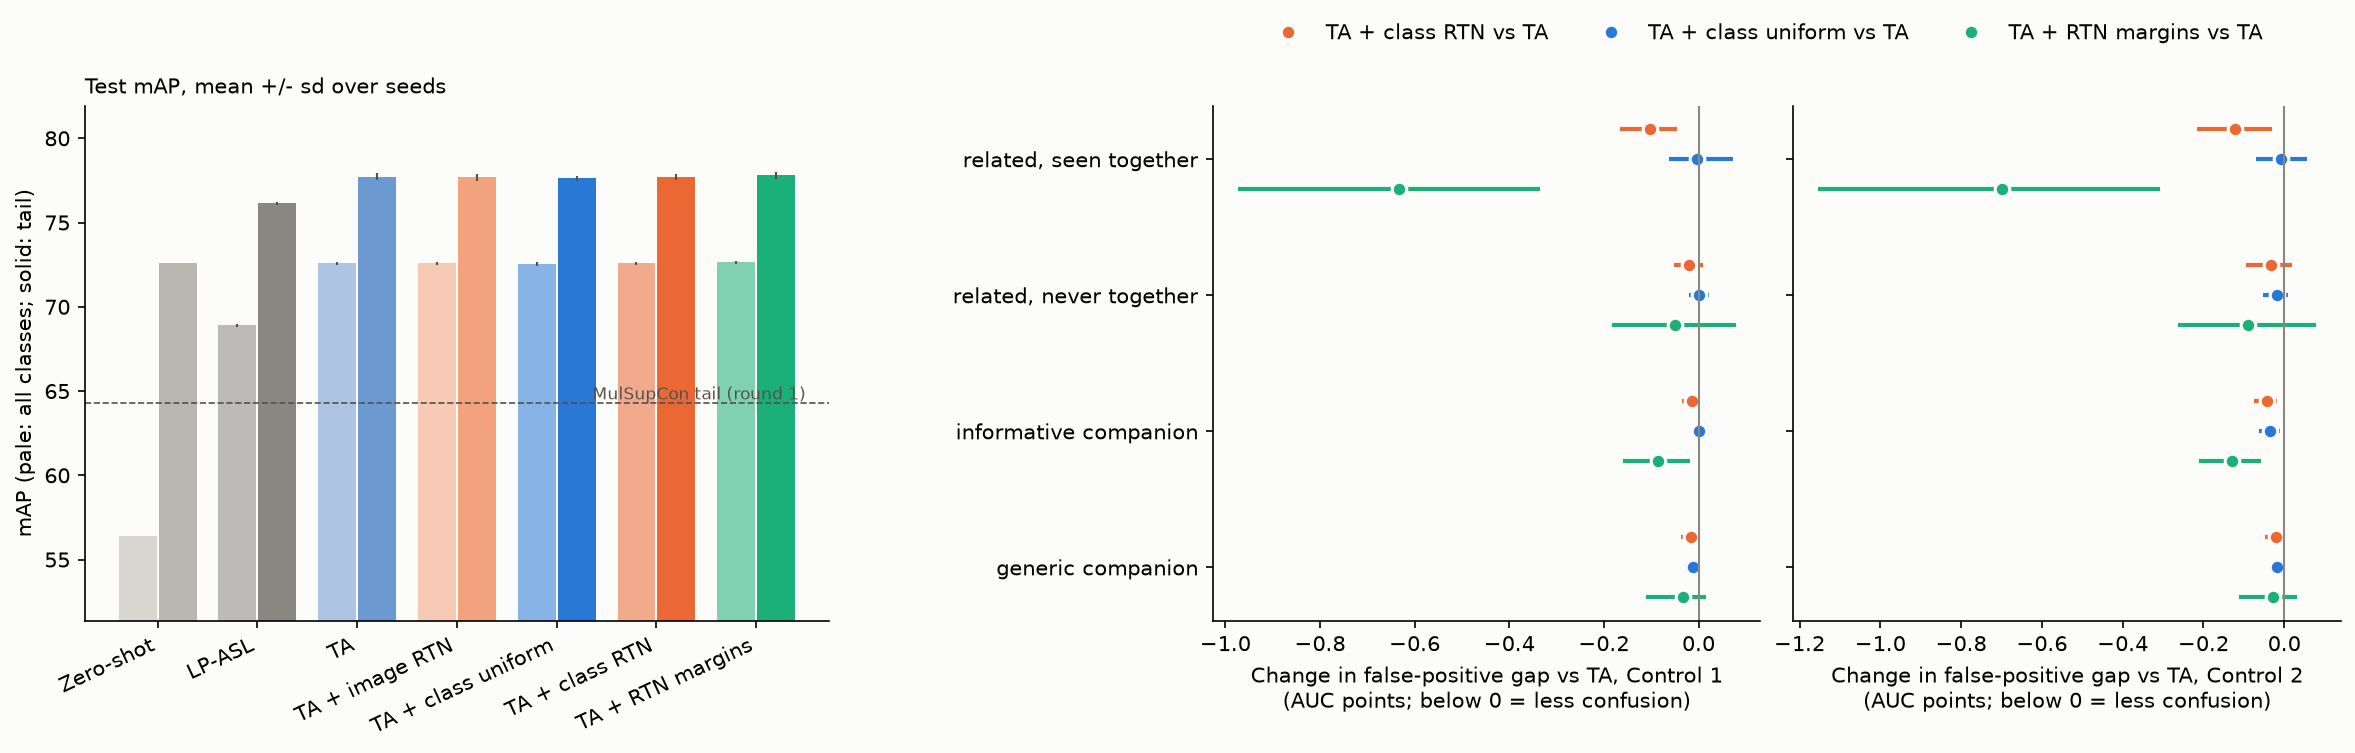

Saved coco_mlt\round4\round4.png


In [12]:
SURFACE, MUTED, INK = "#fcfcfb", "#898781", "#52514e"
COL = {"zs": "#b9b7b0", "lp_bce": "#a19f98", "lp_asl": MUTED, "ta": "#6c99d0",
       "supcon": "#9ab9e0", "rtn": "#f2a27d", "cc_uni": "#2a78d6", "cc_rtn": "#eb6834",
       "margin": "#1baf7a"}
FIG_KEYS = ["zs", "lp_asl", "ta", "rtn", "cc_uni", "cc_rtn", "margin"]
fig = plt.figure(figsize=(16, 5.2), facecolor=SURFACE)
gs_l = fig.add_gridspec(1, 1, left=0.05, right=0.36, bottom=0.2, top=0.86)
gs_r = fig.add_gridspec(1, 2, left=0.52, right=0.99, bottom=0.2, top=0.86, wspace=0.06)
ax0 = fig.add_subplot(gs_l[0])
x = np.arange(len(FIG_KEYS))
for off, g, alpha in ((-0.2, "all", 0.55), (0.2, "tail", 1.0)):
    vals = [[group_map(a, g) for a in AP_SEED[k]] for k in FIG_KEYS]
    ax0.bar(x + off, [np.mean(v) for v in vals], width=0.38, alpha=alpha,
            color=[COL[k] for k in FIG_KEYS],
            yerr=[np.std(v, ddof=1) if len(v) > 1 else 0 for v in vals],
            error_kw=dict(ecolor=INK, lw=1), label=f"{g} mAP")
ax0.axhline(64.27, color=INK, lw=0.8, ls="--")
ax0.text(len(FIG_KEYS) - 0.5, 64.27, "MulSupCon tail (round 1)", fontsize=8,
         color=INK, ha="right", va="bottom")
ax0.set_xticks(x)
ax0.set_xticklabels([SHORT[k] for k in FIG_KEYS], rotation=25, ha="right")
lo = min(group_map(a, g) for k in FIG_KEYS for a in AP_SEED[k] for g in ("all", "tail"))
ax0.set_ylim(max(0, min(lo, 64.27) - 5), None)
ax0.set_ylabel("mAP (pale: all classes; solid: tail)")
ax0.set_title("Test mAP, mean +/- sd over seeds", loc="left", fontsize=10)
ax1 = fig.add_subplot(gs_r[0])
ax2 = fig.add_subplot(gs_r[1], sharey=ax1)
ax2.tick_params(labelleft=False)
ty = np.arange(len(TYPES))[::-1]
for i, ax in enumerate((ax1, ax2)):
    for off, (a, b) in zip((0.22, 0.0, -0.22),
                           (("cc_rtn", "ta"), ("cc_uni", "ta"), ("margin", "ta"))):
        for j in range(len(TYPES)):
            m, l_, h, _ = TYPE_CI[(a, b, i, j)]
            if not np.isfinite(m):
                continue
            ax.hlines(ty[j] + off, l_, h, color=COL[a], lw=2)
            ax.plot(m, ty[j] + off, "o", color=COL[a], ms=7, mec=SURFACE, mew=1.5,
                    label=f"{SHORT[a]} vs TA" if j == 0 else None)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_xlabel(f"Change in false-positive gap vs TA, Control {i + 1}\n"
                  f"(AUC points; below 0 = less confusion)")
ax1.set_yticks(ty)
ax1.set_yticklabels(TYPES)
h_, l_ = ax1.get_legend_handles_labels()
fig.legend(h_, l_, frameon=False, loc="upper center", bbox_to_anchor=(0.75, 0.99), ncol=3)
for a in (ax0, ax1, ax2):
    a.set_facecolor(SURFACE)
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
FIG = os.path.join(OUT, "round4.png")
fig.savefig(FIG, dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.close(fig)
display(Image(filename=FIG))
print(f"Saved {FIG}")

## Step 11: save the results

In [13]:
results_table.to_csv(os.path.join(OUT, "results_round4.csv"), index=False)
raw_table.to_csv(os.path.join(OUT, "results_round4_no_ensemble.csv"), index=False)
cv_table.to_csv(os.path.join(OUT, "cv_round4.csv"), index=False)
comparisons.to_csv(os.path.join(OUT, "comparisons_round4.csv"), index=False)
gap_levels.to_csv(os.path.join(OUT, "gaps_round4.csv"), index=False)
type_changes.to_csv(os.path.join(OUT, "by_type_round4.csv"), index=False)
pd.DataFrame({NAME[k]: AP[k] for k in KEYS}, index=names).to_csv(
    os.path.join(OUT, "per_class_ap_round4.csv"))
with open(os.path.join(OUT, "summary_round4.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n\n" + results_table.to_string(index=False) + "\n")
print("\n".join(lines))
print(f"\nSaved the tables and summary_round4.txt to {os.path.abspath(OUT)}")

TA + relation-typed class contrast (ours) vs TA + class contrast, uniform weights: PARTLY  (tail AP +0.07 [-0.02, +0.18], higher in 7 of 10 seeds; gap reduced under both controls: True; head AP +0.01; overall AP +0.04 [+0.01, +0.07])
TA + relation-typed class contrast (ours) vs CLIP-initialised adapter (TA): PARTLY  (tail AP -0.04 [-0.17, +0.05], higher in 3 of 10 seeds; gap reduced under both controls: True; head AP -0.00; overall AP -0.00 [-0.04, +0.03])
TA + relation-typed margins (ours) vs CLIP-initialised adapter (TA): PARTLY  (tail AP +0.07 [-0.11, +0.25], higher in 7 of 10 seeds; gap reduced under both controls: True; head AP -0.03; overall AP +0.06 [-0.04, +0.16])
TA + relation-typed class contrast (ours) vs Linear probe, ASL: NOT SHOWN  (tail AP +1.56 [-0.27, +3.91], higher in 10 of 10 seeds; gap reduced under both controls: False; head AP +6.42; overall AP +3.68 [+2.66, +4.78])
TA + relation-typed margins (ours) vs Linear probe, ASL: NOT SHOWN  (tail AP +1.66 [-0.12, +3.94], 

## How to read the results

- **TA + class RTN vs TA + class uniform** is the test of the relation
  types at the classifier; **vs TA** shows what the class contrast
  adds at all. **TA + RTN margins vs TA** tests the margins.
- The by-type table shows whether the relation-typed variants reduce
  the confusion types they weight (related classes) and leave the
  others alone, as RTN did in round 2.
- Round 3's rows are repeated for reference (same saved runs).

## Limitations

- Round 4 was designed after seeing round 3, so its verdicts are
  exploratory; a gain must be confirmed on a second dataset (VOC-MLT)
  with every setting fixed in advance.
- Settings are chosen by cross-validation with one seed; the
  relation-typed variants have more settings than their controls,
  which can make their cross-validated score optimistic but not their
  test score.
- The confusion groups and the test images are the same ones that
  motivated the method.